In [1330]:
import pandas as pd
import numpy as np
import math
from PIL import Image

In [1331]:
#img = np.asarray(Image.open("chelovechki/1.png").convert("L")) / float(255.0)
#print(img)

In [1332]:
df = pd.DataFrame({
    'y' : [0] * 0,
    'et': [0] * 0,
    'er': [0] * 0
})

print(df)



Empty DataFrame
Columns: [y, et, er]
Index: []


In [1333]:
def sigma(x):
  res = 0
  if x > 700:
    res = 1
  elif x < -700:
    res = 0
  else: 
    res = 1 / (1 + math.exp(-x))
  return res
def porog(x):
  res = 0
  if x >= 0:
    res = 1
  return res

neironcount = 0

class akson:
  def __init__(self):
    self.wes = 0
  def __repr__(self):
    return str(self.wes)

class neiron:
  def __init__(self):
      global neironcount
      self.aksons = []
      self.neirons = []
      self.id = neironcount
      neironcount += 1
      self.lastvalue = 0
  def getvalue(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

class inputneiron(neiron):
  def setvalue(self, x):
    self.myvalue = x
  def getvalue(self):
    #print(f"в нейроне {self.id} значение {self.myvalue} x")
    self.lastvalue = self.myvalue
    return self.myvalue
  def __init__(self):
    super().__init__()
    self.myvalue = 0

class outputneiron(neiron):
  def getvalue(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

In [1334]:
import random

layer1 = [inputneiron() for i in range(36)]
layer2 = [neiron() for i in range(6)]
layer3 = outputneiron()
biasneiron = inputneiron()
biasneiron.setvalue(1)
neironsall = layer1 + layer2 + [layer3]
aksonsall = []

layer1.append(biasneiron)
layer2.append(biasneiron)
layer3.neirons.append(biasneiron)

for n in layer2:
  n.neirons = layer1
  for j in range(len(layer1)):
    n.aksons.append(akson())

layer3.neirons = layer2
for j in range(len(layer2)):
  layer3.aksons.append(akson())

for n in neironsall:
  for a in n.aksons:
    a.wes = random.uniform(-1, 1)
    aksonsall.append(a)

for a in aksonsall:
  a.wes = random.uniform(-1, 1)

In [1335]:
def showwesa():
  for a in aksonsall:
    print(a.wes)
#print(aksonsall)
showwesa()
print(aksonsall)

-0.9074646796699104
-0.30251225692564754
0.1976656786636939
-0.1474279033893422
0.15575042522182247
0.26663872967698055
-0.4411326743839685
0.43477098030602046
0.6349014576350602
-0.5230002084674354
-0.6331336368452563
-0.4056699533066612
-0.3026498787143206
-0.7022563567191018
0.10321193032258535
0.5155266941641916
0.7628113519581501
0.39255761061609973
0.6408285998667242
-0.6153395904834145
0.248682240934899
0.9605829941713571
-0.9962082069615015
0.1276358114848386
-0.4682896065714337
-0.6063615497508255
0.4406183233701464
0.11814110646675124
0.5904686715617633
0.02080676202922649
0.6091737374227444
0.6000390558917152
-0.3666778772017223
-0.8602791927534794
0.855874829381758
-0.566595414742697
0.17274020684007763
-0.9133963150943516
0.02812258786610844
0.8755099014393348
-0.672995488852923
0.34638198233045614
0.9612370903540577
0.29309328191593353
-0.593337306516381
-0.8069023192935556
-0.6002329917659412
-0.8567732050574446
0.9778421290701749
0.9218639067506702
-0.9071595010054474
-

Теперь надо разобраться с загрузкой датасета и использованием изображений из папки chelovechki

In [1336]:
import requests
import os

## Set the GitHub repository and folder details
repo_url = "https://api.github.com/repos/ashotnafig1/Neironki/contents/Lab02/chelovechki"
local_path = "chelovechki"

os.makedirs(local_path, exist_ok=True)
## Send a GET request to the GitHub API
response = requests.get(repo_url)

## Iterate through the folder contents and download each file
for item in response.json():
    if item["type"] == "file":
        file_url = item["download_url"]
        file_name = item["name"]
        file_path = f"{local_path}/{file_name}"

        ## Download the file
        file_response = requests.get(file_url)
        with open(file_path, "wb") as file:
            file.write(file_response.content)

In [1337]:
# возвращает np массив изображения, причём нормализованный
def readimage(path):
    return np.asarray(Image.open(path).convert("L")) / float(255.0) 

table = pd.read_csv("chelovechki/tablica.txt", sep=' ')
table["y"] = None
table["err"] = None

print(table)

def getimage(number):
    return readimage("chelovechki/" + str(number) + ".png").flatten()
for i in range(len(table)):
    print(getimage(i))

   id  class     y   err
0   0      0  None  None
1   1      0  None  None
2   2      1  None  None
3   3      1  None  None
4   4      0  None  None
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 1. 1. 1. 0. 0.
 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0. 0.
 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0.
 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 1. 1. 1. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]


In [1338]:
#
def Test(X):
  for i in range(len(X)):
    layer1[i].setvalue(X[i])
  return layer3.getvalue()


In [1339]:
def bigtest():
  s = 0
  sq = 0
  for i, clas in table.iterrows():
    X = getimage(i)
    y_pred = Test(X)
    table.loc[i, "y"]  = y_pred
    table.loc[i, "err"] = table.loc[i, "class"] - y_pred
    s += int(table.loc[i, "err"])
    sq += (table.loc[i, "err"])**2
  return float(s), float(sq)

summa, summaq = bigtest()
print(summa, summaq)
print(table)

2.0 2.0
   id  class  y err
0   0      0  0   0
1   1      0  0   0
2   2      1  0   1
3   3      1  0   1
4   4      0  0   0


Всё готово, можно пробовать делать обучение


In [1340]:
param = 0.35

def correctwesa():
  for i in range(len(layer3.aksons)):
      layer3.aksons[i].wes += layer3.neirons[i].getvalue() * -summa * param


correctwesa()
summa, summaq = bigtest()
print(summa, summaq)
print(table)
showwesa()

2.0 2.0
   id  class  y err
0   0      0  0   0
1   1      0  0   0
2   2      1  0   1
3   3      1  0   1
4   4      0  0   0
-0.9074646796699104
-0.30251225692564754
0.1976656786636939
-0.1474279033893422
0.15575042522182247
0.26663872967698055
-0.4411326743839685
0.43477098030602046
0.6349014576350602
-0.5230002084674354
-0.6331336368452563
-0.4056699533066612
-0.3026498787143206
-0.7022563567191018
0.10321193032258535
0.5155266941641916
0.7628113519581501
0.39255761061609973
0.6408285998667242
-0.6153395904834145
0.248682240934899
0.9605829941713571
-0.9962082069615015
0.1276358114848386
-0.4682896065714337
-0.6063615497508255
0.4406183233701464
0.11814110646675124
0.5904686715617633
0.02080676202922649
0.6091737374227444
0.6000390558917152
-0.3666778772017223
-0.8602791927534794
0.855874829381758
-0.566595414742697
0.17274020684007763
-0.9133963150943516
0.02812258786610844
0.8755099014393348
-0.672995488852923
0.34638198233045614
0.9612370903540577
0.29309328191593353
-0.5933373

In [1341]:

#def korrektirowka():
#  for i, row in df.iterrows():


In [1342]:
# это пайтон версия обучения с корректировкой
'''
epohi = 0
while (summaq != 0) and (epohi < 1000):
  correctwesa()
  summa, summaq = bigtest()
  epohi += 1

print(aksonsall)
print("эпох: " + str(epohi))
print(table)
'''

'\nepohi = 0\nwhile (summaq != 0) and (epohi < 1000):\n  correctwesa()\n  summa, summaq = bigtest()\n  epohi += 1\n\nprint(aksonsall)\nprint("эпох: " + str(epohi))\nprint(table)\n'

In [1343]:
# neir это испытуемый нейрон
# i это локальный индекс испытуемого веса (и нейрона на другой стороне тоже)
# BIGerror это квадратичная ошибка
# чтобы не вычислять каждый раз ошибку внутри функции
# её лучше в параметр передавать
# и не важно, что всё равно вычислять придётся, может быть и нет
def getdldw(neir, i, BIGerror):
    y = neir.lastvalue
    x = neir.neirons[i].lastvalue
    res = BIGerror * y * (1 - y) * x
    return res

def getBIGerror():
    s = 0
    sq = 0
    for i, clas in table.iterrows():
        X = getimage(i)
        y_pred = Test(X)
        table.loc[i, "y"]  = y_pred
        table.loc[i, "err"] = table.loc[i, "class"] - y_pred
        s += table.loc[i, "err"]
        sq += (table.loc[i, "err"])**2
    return float(s), float(sq)
    

In [1344]:
# опять поставлю на выходной нейрон сигмоиду чтобы красиво работало
def getvaluePOROG(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

def getvalueSIGMO(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

outputneiron.getvalue = getvalueSIGMO


всё что выше была заготовка самих данных, алгоритма обучения и способов как это связать.
Пора проверять чё я там настрочил

In [1345]:
maloe = 10e-4
speed = 0.1

epohi = 0
bigerrors = []
BIG, BIGQ = getBIGerror()
while BIGQ > maloe and epohi < 2000:
    for i, clas in table.iterrows():
        X = getimage(i)
        y = Test(X)
        e = table.loc[i, "class"]
        for n in neironsall:
            for j in range(len(n.neirons)):
                n.aksons[j].wes += getdldw(n, j, e - y) * speed
    BIG, BIGQ = getBIGerror()
    bigerrors.append(BIGQ)
    epohi += 1
bigerrors.append(BIGQ)

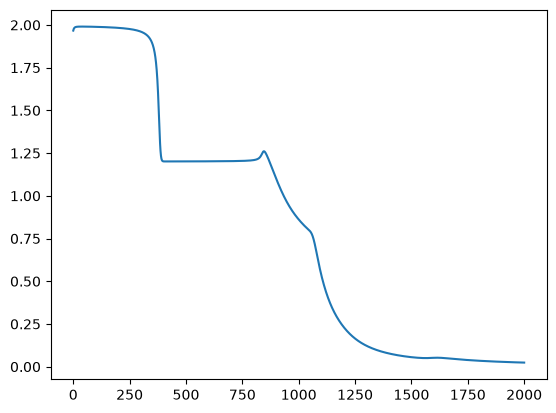

In [1346]:
from matplotlib import pyplot as plt
plt.plot(np.arange(0, epohi + 1), bigerrors)

In [1347]:
print(table)
showwesa()
print(aksonsall)

   id  class         y       err
0   0      0  0.078717 -0.078717
1   1      0  0.062376 -0.062376
2   2      1  0.929639  0.070361
3   3      1   0.92587   0.07413
4   4      0  0.059805 -0.059805
-0.9074646796699104
-0.30251225692564754
0.1976656786636939
-0.1474279033893422
0.15575042522182247
0.26663872967698055
-0.4411326743839685
0.43477098030602046
1.0642795620940322
-1.0502620051235994
-0.6331336368452563
-0.4056699533066612
-0.3026498787143206
-0.27287825226012397
0.005328238125398214
0.417643001967009
0.2355495553019868
0.39255761061609973
0.6408285998667242
-2.6035411586803336
-0.26306097264618267
-1.5548803706817325
-1.937329525001559
0.1276358114848386
-0.4682896065714337
1.811218122905076
0.9005775294001265
-0.4397017917604127
3.038629445788663
0.02080676202922649
0.6091737374227444
0.6000390558917152
-0.3666778772017223
-0.8602791927534794
0.855874829381758
-0.566595414742697
0.07485651464289071
-0.9133963150943516
0.02812258786610844
0.8755099014393348
-0.67299548885292

In [1348]:
outputneiron.getvalue = getvaluePOROG
getBIGerror()
print(table)
showwesa()

   id  class  y err
0   0      0  0   0
1   1      0  0   0
2   2      1  1   0
3   3      1  1   0
4   4      0  0   0
-0.9074646796699104
-0.30251225692564754
0.1976656786636939
-0.1474279033893422
0.15575042522182247
0.26663872967698055
-0.4411326743839685
0.43477098030602046
1.0642795620940322
-1.0502620051235994
-0.6331336368452563
-0.4056699533066612
-0.3026498787143206
-0.27287825226012397
0.005328238125398214
0.417643001967009
0.2355495553019868
0.39255761061609973
0.6408285998667242
-2.6035411586803336
-0.26306097264618267
-1.5548803706817325
-1.937329525001559
0.1276358114848386
-0.4682896065714337
1.811218122905076
0.9005775294001265
-0.4397017917604127
3.038629445788663
0.02080676202922649
0.6091737374227444
0.6000390558917152
-0.3666778772017223
-0.8602791927534794
0.855874829381758
-0.566595414742697
0.07485651464289071
-0.9133963150943516
0.02812258786610844
0.8755099014393348
-0.672995488852923
0.34638198233045614
0.9612370903540577
0.29309328191593353
-0.59333730651638

In [ ]:
import PyQt6 as qt
from PyQt6 import QtWidgets
app = QtWidgets.QApplication()
MainWindow = QtWidgets.QMainWindow()
ui = MainWindow()
ui.setupUi(MainWindow)
MainWindow.show()
